<a href="https://colab.research.google.com/github/Nismata/Nismata-Sigdel/blob/main/HW%2011.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [275]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn. preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [276]:
waves = pd.read_csv('Waves_2023.txt', sep=r'\s+')
waves.describe()

,YY,MM,DD,hh,mm,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,VIS,TIDE
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.000000,17285.0,17285.0,17285.0
mean,2023.0,6.526063,15.800579,11.499277,40.985594,999.0,99.0,99.0,1.083535,12.161879,6.813054,234.556205,9999.0,999.0,17.196535,999.0,99.0,99.0
std,0.0,3.467253,8.817920,6.925343,15.007646,0.0,0.0,0.0,2.296129,4.165737,2.803208,49.429981,0.0,0.0,2.564664,0.0,0.0,0.0
min,2023.0,1.000000,1.000000,0.000000,0.000000,999.0,99.0,99.0,0.330000,2.860000,3.420000,10.000000,9999.0,999.0,11.800000,999.0,99.0,99.0
25%,2023.0,4.000000,8.000000,5.000000,26.000000,999.0,99.0,99.0,0.730000,9.090000,5.500000,179.000000,9999.0,999.0,14.600000,999.0,99.0,99.0
50%,2023.0,6.000000,16.000000,11.000000,26.000000,999.0,99.0,99.0,0.880000,12.500000,6.360000,263.000000,9999.0,999.0,17.500000,999.0,99.0,99.0
75%,2023.0,10.000000,23.000000,18.000000,56.000000,999.0,99.0,99.0,1.140000,14.290000,7.550000,271.000000,9999.0,999.0,19.400000,999.0,99.0,99.0
max,2023.0,12.000000,31.000000,23.000000,56.000000,999.0,99.0,99.0,99.000000,99.000000,99.000000,999.000000,9999.0,999.0,23.900000,999.0,99.0,99.0


In [277]:
waves = waves[["WVHT", "DPD", "APD", "MWD","WTMP",]].copy()

In [278]:
# WVHT = Wave Height (m)
# DPD = Dominant wave period (seconds)
# APD = Average wave period (seconds)
# MWD = The direction from which the waves at the dominant period (DPD) are coming
# WTMP = Sea surface temperature (Celsius)

waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]
waves=waves[waves['WTMP']<999]

In [279]:
waves = waves.dropna()
waves.head()

,WVHT,DPD,APD,MWD,WTMP
0,1.12,12.50,7.69,269,15.3
1,1.16,11.76,7.34,272,15.3
2,1.20,12.50,7.08,268,15.3
3,1.25,10.53,7.33,268,15.4
4,1.27,10.53,7.57,268,15.5


In [280]:
scaler = StandardScaler()
waves_scaled = scaler.fit_transform(waves)

pca = PCA()
PC_scores = pca.fit_transform(waves_scaled)

variance = pca.explained_variance_ratio_ * 100
cumulative_variance = np.cumsum(variance)

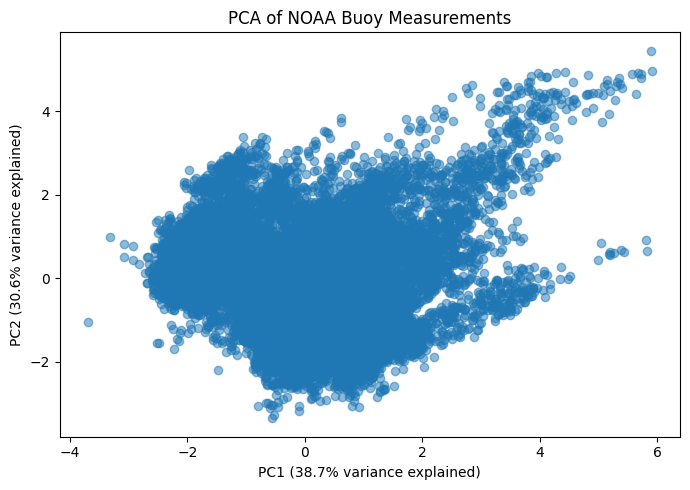

In [281]:
plt.figure(figsize=(7, 5))

plt.scatter(PC_scores[:, 0], PC_scores[:, 1], alpha=0.5)

plt.xlabel(f"PC1 ({variance[0]:.1f}% variance explained)")
plt.ylabel(f"PC2 ({variance[1]:.1f}% variance explained)")
plt.title("PCA of NOAA Buoy Measurements")

plt.tight_layout()
plt.show()

,PC,Variance explained (%),Cumulative variance (%)
0,PC1,38.74,38.74
1,PC2,30.61,69.36
2,PC3,14.39,83.74
3,PC4,10.63,94.38
4,PC5,5.62,100.00


Number of PCs needed to explain at least 90%: 4


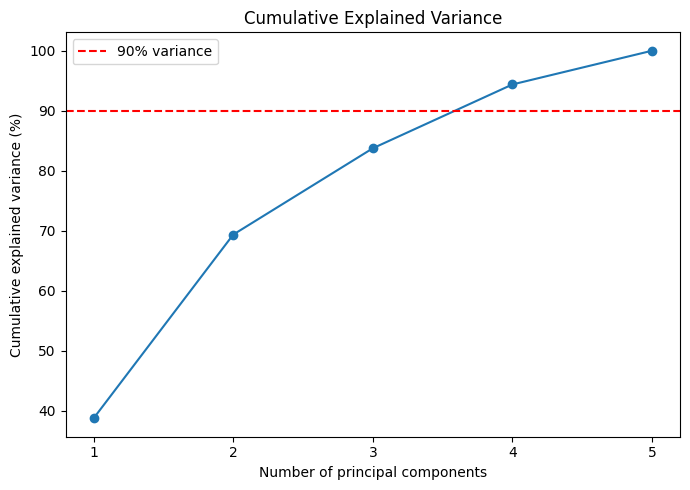

In [282]:
variance_table = pd.DataFrame({
    "PC": ["PC1", "PC2", "PC3", "PC4", "PC5"],
    "Variance explained (%)": variance,
    "Cumulative variance (%)": cumulative_variance
})

display(variance_table.round(2))

number_PCs = np.searchsorted(cumulative_variance, 90) + 1

print("Number of PCs needed to explain at least 90%:", number_PCs)

plt.figure(figsize=(7, 5))

plt.plot([1, 2, 3, 4, 5], cumulative_variance, "o-")
plt.axhline(90, color="red", linestyle="--", label="90% variance")

plt.xticks([1, 2, 3, 4, 5])
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance (%)")
plt.title("Cumulative Explained Variance")
plt.legend()

plt.tight_layout()
plt.show()

In [283]:
contributions = pd.DataFrame(
    pca.components_.T ** 2 * 100,
    index=waves.columns,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"]
)

display(contributions.round(2))

,PC1,PC2,PC3,PC4,PC5
WVHT,29.29,3.80,14.17,49.61,3.13
DPD,3.77,49.83,7.53,0.31,38.56
APD,10.37,38.57,5.37,16.62,29.07
MWD,32.13,7.76,2.20,31.99,25.92
WTMP,24.43,0.04,70.73,1.47,3.32


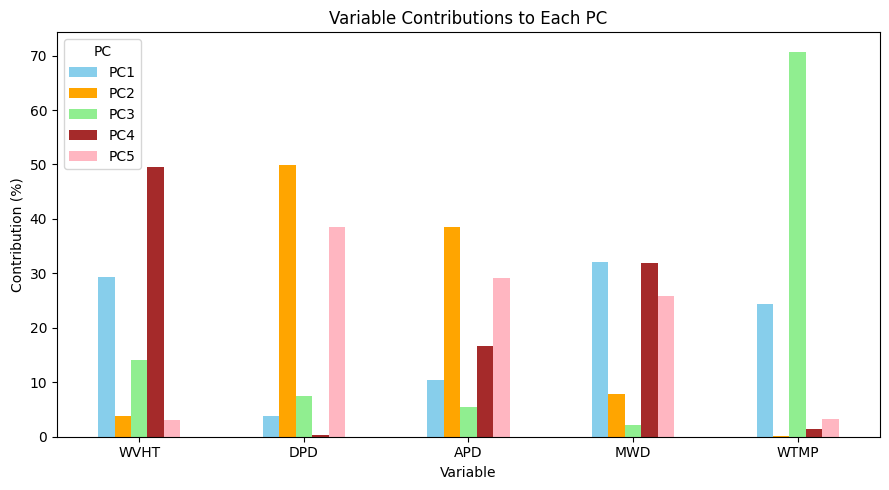

In [284]:
contributions.plot.bar(
    figsize=(9, 5),
    color=["skyblue", "orange","lightgreen", "brown","lightpink"])

plt.xlabel("Variable")
plt.ylabel("Contribution (%)")
plt.title("Variable Contributions to Each PC")
plt.xticks(rotation=0)
plt.legend(title="PC")

plt.tight_layout()
plt.show()

<Axes: >

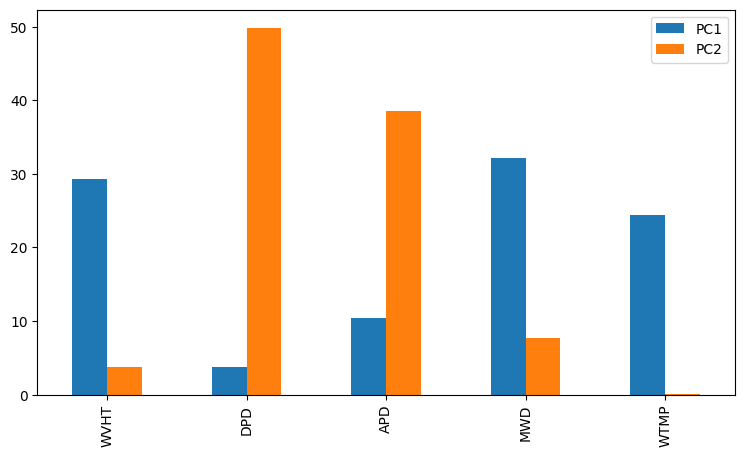

In [285]:
contributions[["PC1", "PC2"]].plot.bar(figsize=(9, 5))

In [286]:
from sklearn.cluster import KMeans

PC_data = PC_scores[:, :2]

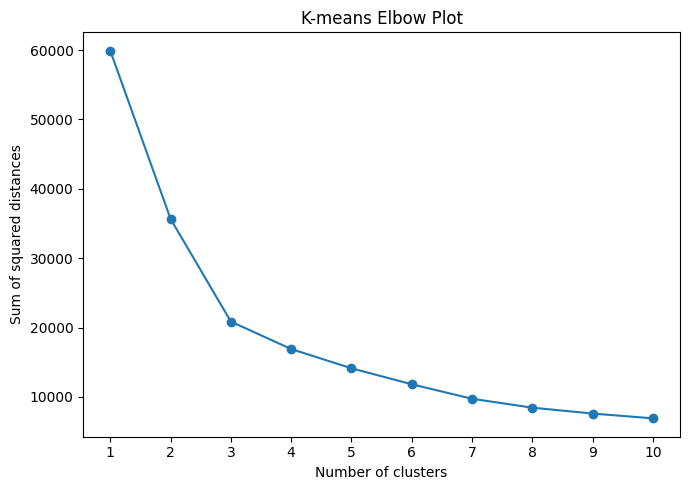

In [287]:
cluster_numbers = range(1, 11)
squared_distances = []

for k in cluster_numbers:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(PC_data)
    squared_distances.append(model.inertia_)

plt.figure(figsize=(7, 5))

plt.plot(cluster_numbers, squared_distances, "o-")

plt.xticks(cluster_numbers)
plt.xlabel("Number of clusters")
plt.ylabel("Sum of squared distances")
plt.title("K-means Elbow Plot")

plt.tight_layout()
plt.show()

/tmp/ipykernel_2093/3859317563.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


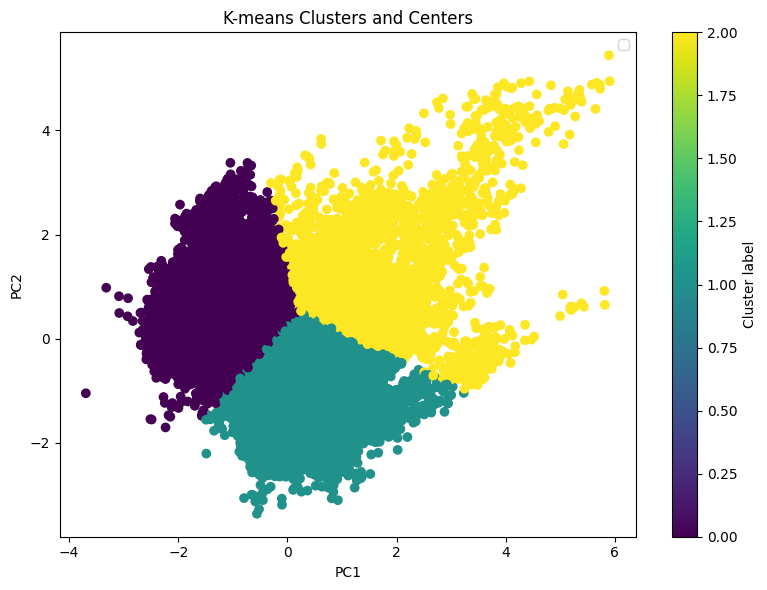

In [288]:
# choosing 3 clusters based on the elbow plot

chosen_k = 3
kmeans = KMeans(
n_clusters=chosen_k,
random_state=42,
n_init=10
)

cluster_labels = kmeans.fit_predict(PC_data)
plt.figure(figsize=(8, 6))

points = plt.scatter(
PC_data[:, 0],
PC_data[:, 1],
c=cluster_labels,
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-means Clusters and Centers")
plt.colorbar(points, label="Cluster label",)
plt.legend()

plt.tight_layout()
plt.show()

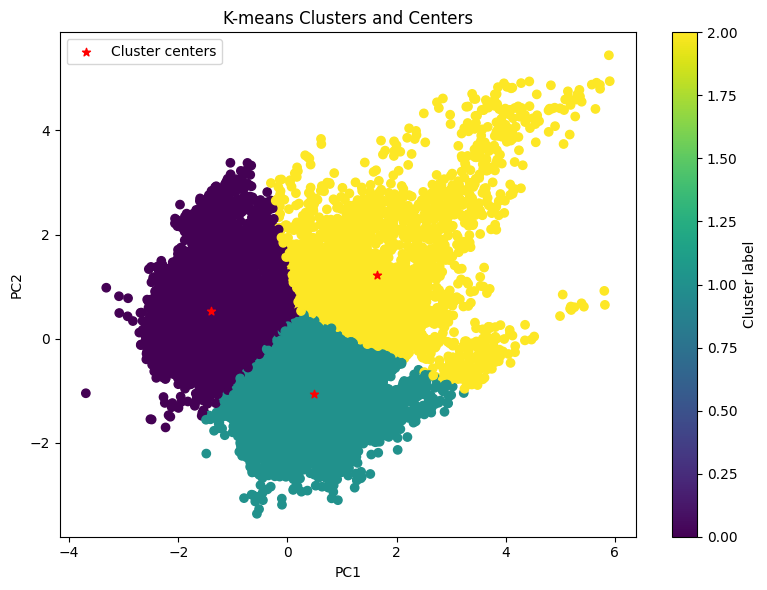

In [289]:
centers = kmeans.cluster_centers_

plt.figure(figsize=(8, 6))

points = plt.scatter(
    PC_data[:, 0],
    PC_data[:, 1],
    c=cluster_labels
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    color="red",
    marker="*",
    label="Cluster centers"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-means Clusters and Centers")
plt.colorbar(points, label="Cluster label")
plt.legend()
plt.tight_layout()
plt.show()